# Bank Database CPU Forecast and Auto-Scaling (v2)
**Goal:** predict a CPU overload (above 85%) 5, 15 and 30 minutes ahead, on **any date and at any hour**, and add cores before it happens.

Run the cells from top to bottom. Before this notebook, run `load_transactions_mysql_v2.py` once.
Cells marked **[slow]** take a few minutes.

## 1. Connect to MySQL

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

PASSWORD = "MY PASSWORD"
engine = create_engine(URL.create("mysql+pymysql", username="root", password=PASSWORD,
                                  host="localhost", port=3306, database="bank_db"))
START, DAYS = "2025-07-03", 150

## 2. Read the telemetry view **[slow]**
The view `v_live_bank_telemetry` joins customers, accounts and transactions and counts transactions per minute.
The result is saved to a CSV so we do not wait again. **Delete `telemetry_view_v2.csv` if you ever reload the transactions.**

In [2]:
if os.path.exists("telemetry_view_v2.csv"):
    df = pd.read_csv("telemetry_view_v2.csv", parse_dates=["minute_ts"])
else:
    df = pd.read_sql("SELECT minute_ts, txn_count FROM v_live_bank_telemetry", engine)
    df["minute_ts"] = pd.to_datetime(df["minute_ts"])
    df.to_csv("telemetry_view_v2.csv", index=False)
print(df.shape)
df.head()

(177674, 2)


,minute_ts,txn_count
0,2025-07-03 00:00:00,2
1,2025-07-03 00:03:00,1
2,2025-07-03 00:06:00,3
3,2025-07-03 00:07:00,4
4,2025-07-03 00:08:00,1


## 3. One row for every minute
The view skips minutes with no transactions. For a time series every minute must exist, so empty minutes become 0.

In [3]:
full_index = pd.date_range(START, periods=DAYS * 1440, freq="1min")
load = df.set_index("minute_ts")["txn_count"].reindex(full_index).fillna(0).astype(int)
load.name = "tx_per_min"
print("minutes:", len(load), "| total transactions:", load.sum(), "| empty minutes:", (load == 0).sum())
load.describe()

minutes: 216000 | total transactions: 1000000 | empty minutes: 38326


count    216000.00000
mean          4.62963
std           5.94368
min           0.00000
25%           1.00000
50%           3.00000
75%           6.00000
max          80.00000
Name: tx_per_min, dtype: float64

## 4. Exploratory analysis of the load

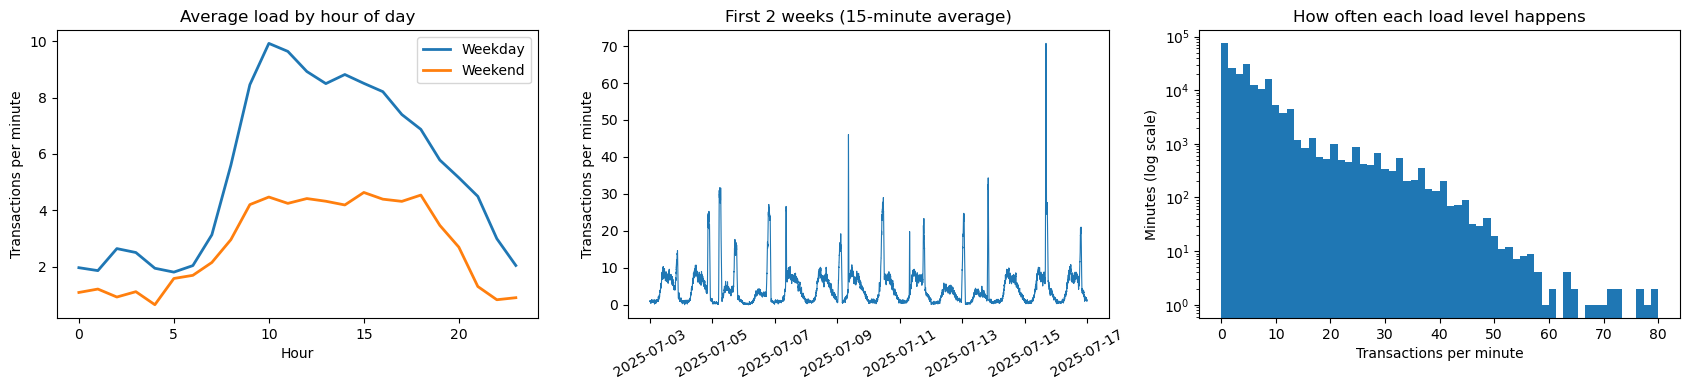

0.500     3.0
0.900    10.0
0.990    32.0
0.999    45.0
Name: tx_per_min, dtype: float64


In [4]:
hour = load.index.hour
weekend = load.index.dayofweek >= 5
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(load[~weekend].groupby(hour[~weekend]).mean(), label="Weekday", lw=2)
ax[0].plot(load[weekend].groupby(hour[weekend]).mean(), label="Weekend", lw=2)
ax[0].set(title="Average load by hour of day", xlabel="Hour", ylabel="Transactions per minute"); ax[0].legend()
w = load.iloc[:14 * 1440].rolling(15).mean()
ax[1].plot(w, lw=0.8); ax[1].set(title="First 2 weeks (15-minute average)", ylabel="Transactions per minute")
ax[1].tick_params(axis="x", rotation=30)
ax[2].hist(load, bins=60); ax[2].set_yscale("log")
ax[2].set(title="How often each load level happens", xlabel="Transactions per minute", ylabel="Minutes (log scale)")
plt.tight_layout(); plt.savefig("fig1_eda_load.png", dpi=130); plt.show()
print(load.quantile([.5, .9, .99, .999]))

## 5. Simulate the server CPU
No real bank server exists in this project, so CPU is **calculated** from the load: more load raises CPU, more cores lower it.
`cpu4` is the CPU the server would show **with 4 cores**. We forecast this value, so that adding cores does not look like a drop in load.

Minutes above 85% with 4 cores: 6549 (3.0% of time)
Minutes above 85% with 8 cores: 182


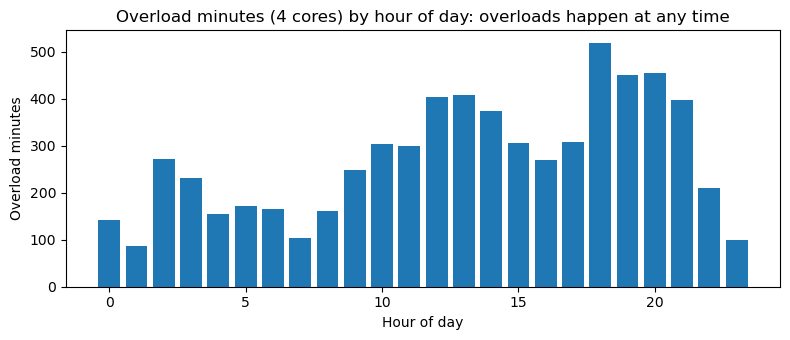

In [5]:
CAPACITY, IDLE, GAMMA, NOISE_SD = 6.1, 5.0, 1.1, 1.5       # transactions/min per core, idle CPU %, contention, noise
UP, DOWN = 85, 40

load_eff = load.ewm(span=5, adjust=False).mean()           # CPU follows a 5-minute average of load
eps = np.random.default_rng(43).normal(0, NOISE_SD, len(load))   # fixed random noise

def cpu_from_load(load_eff, cores, eps):
    u = load_eff / (cores * CAPACITY)                      # how full the server is (1.0 = full)
    return np.clip(IDLE + (100 - IDLE) * np.power(u, GAMMA) + eps, 1, 100)

cpu4 = pd.Series(cpu_from_load(load_eff, 4, eps), index=load.index)
cpu8 = pd.Series(cpu_from_load(load_eff, 8, eps), index=load.index)
print("Minutes above 85% with 4 cores:", int((cpu4 > UP).sum()), f"({(cpu4 > UP).mean()*100:.1f}% of time)")
print("Minutes above 85% with 8 cores:", int((cpu8 > UP).sum()))
over_by_hour = (cpu4 > UP).groupby(cpu4.index.hour).sum()
plt.figure(figsize=(8, 3.5)); plt.bar(over_by_hour.index, over_by_hour.values)
plt.title("Overload minutes (4 cores) by hour of day: overloads happen at any time")
plt.xlabel("Hour of day"); plt.ylabel("Overload minutes"); plt.tight_layout()
plt.savefig("fig2_overload_by_hour.png", dpi=130); plt.show()

## 6. Features: what the model is allowed to see
Only **recent history**: the load and CPU 1-60 minutes ago, recent averages and maximums, and whether load is rising or falling.
There are **no date, weekday, hour or salary-day clues**, so the model must work on any day and at any time.

In [6]:
def make_features(tx, cpu):
    d = pd.DataFrame({"tx_now": tx, "cpu_now": cpu})
    for k in [1, 5, 15, 30, 60]:
        d[f"tx_lag_{k}"] = d["tx_now"].shift(k)
        d[f"cpu_lag_{k}"] = d["cpu_now"].shift(k)
    for w in [5, 10, 15, 20, 40, 60]:
        d[f"tx_mean_{w}"] = d["tx_now"].rolling(w).mean()
    for w in [5, 15, 60]:
        d[f"tx_max_{w}"] = d["tx_now"].rolling(w).max()
        d[f"cpu_mean_{w}"] = d["cpu_now"].rolling(w).mean()
        d[f"cpu_max_{w}"] = d["cpu_now"].rolling(w).max()
    d["tx_slope_5_15"] = d["tx_mean_5"] - d["tx_mean_15"]       # rising (+) or falling (-) load
    d["tx_slope_5_10"] = d["tx_mean_5"] - d["tx_mean_10"]
    d["tx_slope_10_20"] = d["tx_mean_10"] - d["tx_mean_20"]
    d["tx_slope_20_40"] = d["tx_mean_20"] - d["tx_mean_40"]
    d["tx_slope_15_60"] = d["tx_mean_15"] - d["tx_mean_60"]
    d["cpu_change_5"] = d["cpu_now"] - d["cpu_lag_5"]
    return d

HORIZONS = [5, 15, 30]
data = make_features(load, cpu4)
for h in HORIZONS:
    data[f"target_{h}"] = cpu4.shift(-h)                    # CPU h minutes LATER
feature_cols = [c for c in data.columns if not c.startswith("target_")]
clean = data.dropna()
print(len(feature_cols), "features |", len(clean), "usable minutes")

33 features | 215910 usable minutes


## 7. Time-ordered split (70% train, 15% validation, 15% test)
No shuffling: the model learns from the past and is tested on the future. A 30-minute gap at each boundary stops any leakage.

In [7]:
n = len(clean); a, b = int(n * 0.70), int(n * 0.85); GAP = 30
train, val, test = clean.iloc[:a - GAP], clean.iloc[a:b - GAP], clean.iloc[b:]
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {len(part):>7,} rows   {part.index[0]:%d %b %Y} to {part.index[-1]:%d %b %Y}")
ti = test.index
print("overload minutes in the test period with 4 cores:", int((cpu4.loc[ti] > UP).sum()))

train      151,107 rows   03 Jul 2025 to 15 Oct 2025
validation  32,356 rows   15 Oct 2025 to 07 Nov 2025
test        32,387 rows   07 Nov 2025 to 29 Nov 2025
overload minutes in the test period with 4 cores: 960


## 8. Train XGBoost and LightGBM for 5, 15 and 30 minutes ahead
For each horizon both models are trained; the one with the lower **validation** error is kept. The test set is used only for the final score.

In [8]:
from sklearn.metrics import mean_absolute_error, precision_score, recall_score

def candidate_models():
    out = {}
    try:
        from xgboost import XGBRegressor
        out["XGBoost"] = lambda: XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8,
                                              colsample_bytree=0.8, eval_metric="mae", early_stopping_rounds=40, random_state=42)
    except ImportError:
        pass
    try:
        from lightgbm import LGBMRegressor
        out["LightGBM"] = lambda: LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, subsample=0.8,
                                                subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
    except ImportError:
        pass
    if not out:
        from sklearn.ensemble import HistGradientBoostingRegressor
        print("xgboost / lightgbm not installed: using a scikit-learn stand-in")
        out["HistGB (stand-in)"] = lambda: HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_depth=6, random_state=42)
    return out

def fit_model(name, make, Xtr, ytr, Xva, yva):
    m = make()
    if name == "XGBoost":
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    elif name == "LightGBM":
        import lightgbm as lgb
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1", callbacks=[lgb.early_stopping(40, verbose=False)])
    else:
        m.fit(Xtr, ytr)
    return m

models, fc, rows = {}, {}, []
for h in HORIZONS:
    tgt = f"target_{h}"
    fitted, val_mae = {}, {}
    for name, make in candidate_models().items():
        fitted[name] = fit_model(name, make, train[feature_cols], train[tgt], val[feature_cols], val[tgt])
        val_mae[name] = mean_absolute_error(val[tgt], np.clip(fitted[name].predict(val[feature_cols]), 0, 100))
    best = min(val_mae, key=val_mae.get)
    models[h] = fitted[best]
    p = np.clip(models[h].predict(test[feature_cols]), 0, 100)
    fc[h] = pd.Series(p, index=ti)
    ok = test[tgt].notna().values
    y, yp = test[tgt].values[ok], p[ok]
    rows.append({"horizon_min": h, "model": best, "validation_MAE": round(val_mae[best], 3),
                 "model_MAE": round(mean_absolute_error(y, yp), 3),
                 "naive_MAE": round(mean_absolute_error(y, test["cpu_now"].values[ok]), 3),
                 "overload_minutes": int((y > UP).sum()),
                 "precision": round(precision_score(y > UP, yp > UP), 3),
                 "recall": round(recall_score(y > UP, yp > UP), 3)})
    print(f"h={h:>2} validation MAE {({k: round(v, 2) for k, v in val_mae.items()})} -> keep {best}")
metrics = pd.DataFrame(rows)
metrics

h= 5 validation MAE {'XGBoost': 3.17, 'LightGBM': 3.18} -> keep XGBoost
h=15 validation MAE {'XGBoost': 4.04, 'LightGBM': 4.04} -> keep LightGBM
h=30 validation MAE {'XGBoost': 5.27, 'LightGBM': 5.36} -> keep XGBoost


,horizon_min,model,validation_MAE,model_MAE,naive_MAE,overload_minutes,precision,recall
0,5,XGBoost,3.170,2.824,3.580,960,0.938,0.934
1,15,LightGBM,4.039,3.329,4.285,960,0.913,0.826
2,30,XGBoost,5.265,4.110,5.191,960,0.891,0.647


**How to read it:** `model_MAE` is the average mistake in CPU points; `naive_MAE` is the lazy guess "CPU stays as it is now".
`precision` = when the model warns, how often it is right. `recall` = how many real overloads it warned about.

## 9. Which clues mattered most? (30 minutes ahead)

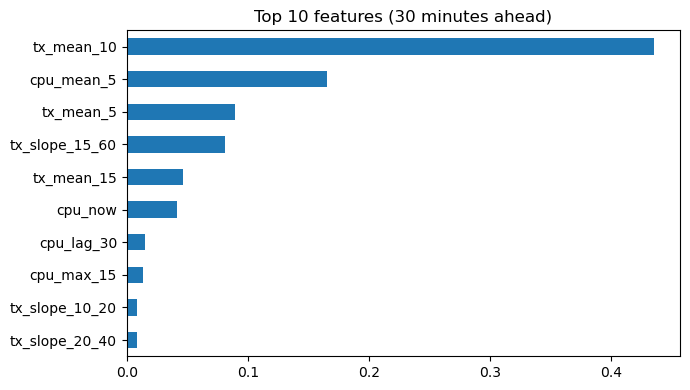

In [9]:
if hasattr(models[30], "feature_importances_"):
    imp = pd.Series(models[30].feature_importances_, index=feature_cols).sort_values().tail(10)
    plt.figure(figsize=(7, 4)); imp.plot(kind="barh"); plt.title("Top 10 features (30 minutes ahead)")
    plt.tight_layout(); plt.savefig("fig3_feature_importance.png", dpi=130); plt.show()
else:
    print("This model type has no feature importances (XGBoost and LightGBM do).")

## 10. Does it warn before each overload starts?
An **episode** is a stretch of overload minutes with no overload in the 60 minutes before it. For every episode we check whether the forecast crossed 85% **before** the real CPU did.

In [10]:
c4t = cpu4.loc[ti].values
multi_fc = np.maximum.reduce([fc[5].values, fc[15].values, fc[30].values])    # any horizon warns -> warn

def episode_leads(forecast, window=45):
    over = c4t > UP
    starts = [i for i in range(1, len(over)) if over[i] and not over[max(0, i - 60):i].any()]
    leads = []
    for s in starts:
        warned = [k for k in range(max(0, s - window), s + 1) if forecast[k] > UP]
        leads.append(s - min(warned) if warned else 0)
    return np.array(leads)

lead_rows = []
for name, f in [("30-min forecast only", fc[30].values), ("5/15/30 combined", multi_fc)]:
    L = episode_leads(f)
    lead_rows.append({"forecast": name, "overload_episodes": len(L), "warned_before_onset": int((L > 0).sum()),
                      "warned_10+_min_ahead": int((L >= 10).sum()),
                      "median_warning_min": float(np.median(L[L > 0])) if (L > 0).any() else 0})
lead_table = pd.DataFrame(lead_rows); lead_table

,forecast,overload_episodes,warned_before_onset,warned_10+_min_ahead,median_warning_min
0,30-min forecast only,11,9,9,15.0
1,5/15/30 combined,11,11,9,13.0


## 11. Auto-scaling policies
| Policy | Rule |
|---|---|
| static4 | never add cores |
| always8 | always 8 cores (best possible, most expensive) |
| reactive | add cores once the CPU is already above 85% |
| predictive_h30 | add cores when the 30-minute forecast is above 85% |
| **predictive** | add cores when **any** forecast (5, 15 or 30 min) is above 85% |
| hybrid | predictive plus the reactive rule as a safety net |

All policies: remove cores after 10 minutes below 40%, wait 10 minutes after any decision, and new cores take 5 minutes to arrive.

In [11]:
load_t = load_eff.loc[ti].values
eps_t = pd.Series(eps, index=load.index).loc[ti].values
cpu4_t = cpu4.loc[ti].values
BASE_CORES, MAX_CORES, DOWN_MIN, COOLDOWN = 4, 8, 10, 10

def cpu_at(load_v, cores, noise):
    u = load_v / (cores * CAPACITY)
    return min(100, max(1, IDLE + (100 - IDLE) * u ** GAMMA + noise))

def simulate(policy, forecast=None, delay=5):
    n = len(load_t)
    cores = MAX_CORES if policy == "always8" else BASE_CORES
    target, pending, last_decision, low_streak = cores, [], -10**9, 0
    cores_log, cpu_log, action = np.zeros(n, int), np.zeros(n), [""] * n
    for t in range(n):
        while pending and pending[0][0] <= t:
            cores = pending.pop(0)[1]
        cpu_now = cpu_at(load_t[t], cores, eps_t[t])
        cores_log[t], cpu_log[t] = cores, cpu_now
        if policy in ("static4", "always8"):
            continue
        if policy == "reactive":
            want_up, low = cpu_now > UP, cpu4_t[t] < DOWN
        else:
            want_up = forecast[t] > UP
            if policy == "hybrid":
                want_up = want_up or cpu_now > UP
            low = forecast[t] < DOWN and cpu4_t[t] < DOWN
        low_streak = low_streak + 1 if low else 0
        if t - last_decision >= COOLDOWN:
            if want_up and target < MAX_CORES:
                target = MAX_CORES; pending.append((t + delay, MAX_CORES)); last_decision, action[t] = t, "SCALE_UP"
            elif low_streak >= DOWN_MIN and target > BASE_CORES:
                target = BASE_CORES; pending.append((t + delay, BASE_CORES)); last_decision, action[t] = t, "SCALE_DOWN"
    return pd.DataFrame({"cores": cores_log, "cpu_actual": cpu_log, "action": action}, index=ti)

def summarize(name, sim):
    over = (sim["cpu_actual"] > UP).values
    return {"policy": name, "overload_minutes": int(over.sum()),
            "overload_episodes": int(((~np.r_[False, over[:-1]]) & over).sum()),
            "extra_core_minutes": int((sim["cores"] - BASE_CORES).sum()),
            "scale_events": int((sim["action"] != "").sum())}

sims = {"static4": simulate("static4"), "always8": simulate("always8"), "reactive": simulate("reactive"),
        "predictive_h30": simulate("predictive", forecast=fc[30].values),
        "predictive": simulate("predictive", forecast=multi_fc),
        "hybrid": simulate("hybrid", forecast=multi_fc)}
policy_table = pd.DataFrame([summarize(k, v) for k, v in sims.items()])
policy_table

,policy,overload_minutes,overload_episodes,extra_core_minutes,scale_events
0,static4,960,49,0,0
1,always8,9,5,129548,0
2,reactive,50,20,5164,24
3,predictive_h30,43,8,5560,20
4,predictive,16,7,5844,24
5,hybrid,16,7,5844,24


## 12. What if new cores take longer to arrive?
Real cloud scaling can take many minutes. The table shows overload minutes for different delays.

In [12]:
rows = []
for d in [0, 5, 10, 15, 20, 30]:
    r = {"delay_min": d}
    for name, pol, f in [("static4", "static4", None), ("reactive", "reactive", None),
                         ("predictive_h30", "predictive", fc[30].values), ("predictive", "predictive", multi_fc),
                         ("hybrid", "hybrid", multi_fc), ("always8", "always8", None)]:
        r[name] = summarize(name, simulate(pol, forecast=f, delay=d))["overload_minutes"]
    rows.append(r)
delay_table = pd.DataFrame(rows); delay_table

,delay_min,static4,reactive,predictive_h30,predictive,hybrid,always8
0,0,960,22,43,11,11,9
1,5,960,50,43,16,16,9
2,10,960,88,43,24,24,9
3,15,960,129,49,30,30,9
4,20,960,177,70,49,49,9
5,30,960,258,126,105,105,9


## 13. Policy comparison charts

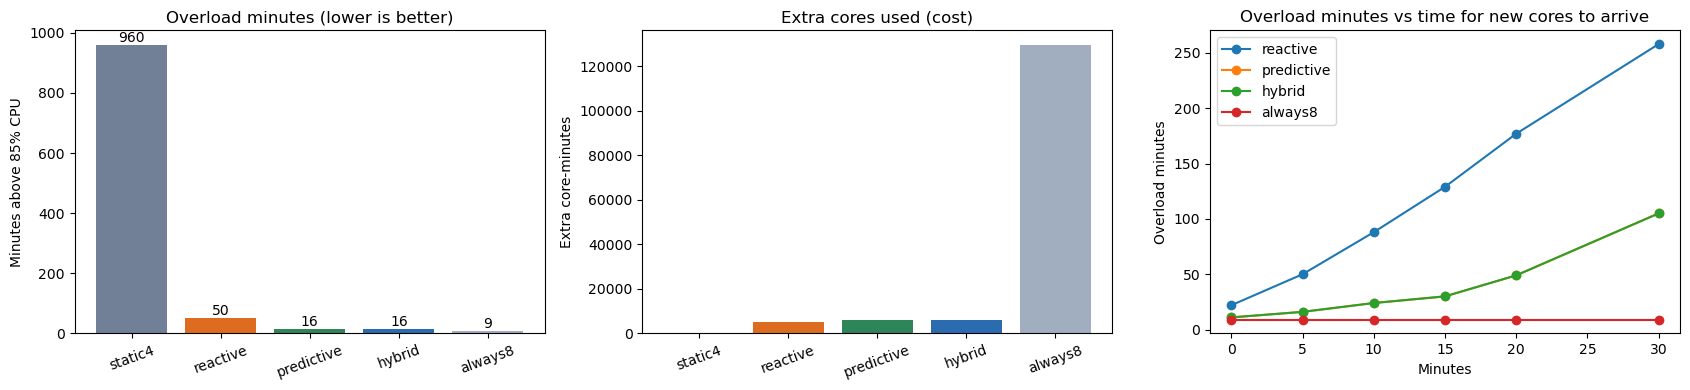

In [13]:
show = ["static4", "reactive", "predictive", "hybrid", "always8"]
p = policy_table.set_index("policy").loc[show]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].bar(show, p["overload_minutes"], color=["#718096", "#dd6b20", "#2f855a", "#2b6cb0", "#a0aec0"])
for i, v in enumerate(p["overload_minutes"]): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set(title="Overload minutes (lower is better)", ylabel="Minutes above 85% CPU")
ax[1].bar(show, p["extra_core_minutes"], color=["#718096", "#dd6b20", "#2f855a", "#2b6cb0", "#a0aec0"])
ax[1].set(title="Extra cores used (cost)", ylabel="Extra core-minutes")
for name in ["reactive", "predictive", "hybrid", "always8"]:
    ax[2].plot(delay_table["delay_min"], delay_table[name], marker="o", label=name)
ax[2].set(title="Overload minutes vs time for new cores to arrive", xlabel="Minutes", ylabel="Overload minutes"); ax[2].legend()
for a_ in ax[:2]: a_.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("fig4_policy_comparison.png", dpi=130); plt.show()

## 14. Pick a day to show, and plot it
The day where predictive scaling saved the most overload minutes compared with reactive scaling.

            static4  reactive  predictive  saved_vs_reactive
2025-11-19      115        15           6                  9
2025-11-20      141         6           0                  6
2025-11-18       87         5           0                  5
2025-11-11      105         4           0                  4
2025-11-26       67         4           0                  4
Demo day: 2025-11-19


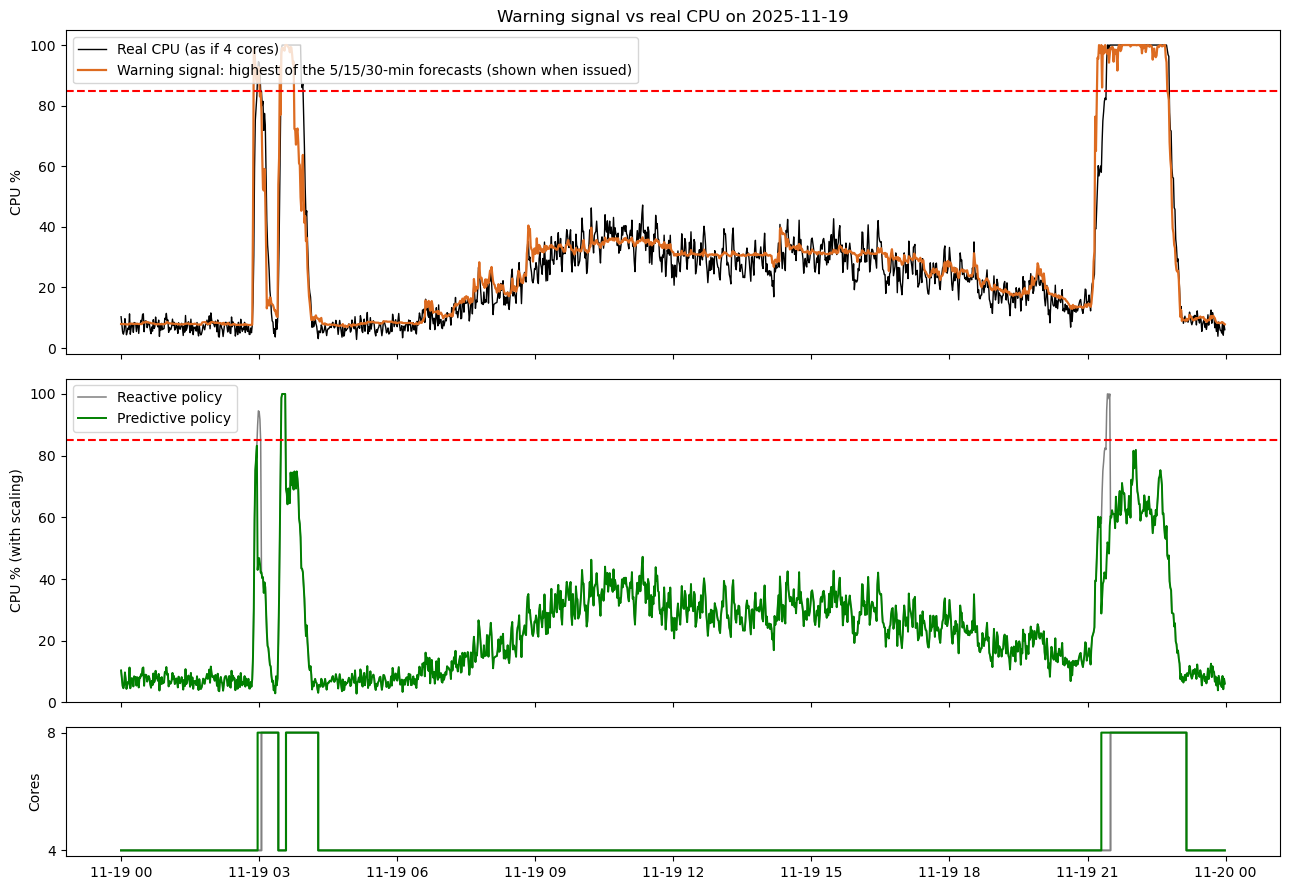

reactive [('02:58', 'SCALE_UP'), ('03:20', 'SCALE_DOWN'), ('03:30', 'SCALE_UP'), ('04:12', 'SCALE_DOWN'), ('21:25', 'SCALE_UP'), ('23:04', 'SCALE_DOWN')]
predictive [('02:53', 'SCALE_UP'), ('03:20', 'SCALE_DOWN'), ('03:30', 'SCALE_UP'), ('04:12', 'SCALE_DOWN'), ('21:13', 'SCALE_UP'), ('23:04', 'SCALE_DOWN')]


In [17]:
day_of = pd.Series(ti.strftime("%Y-%m-%d"), index=ti)
per_day = pd.DataFrame({k: (sims[k]["cpu_actual"] > UP).groupby(day_of).sum() for k in ["static4", "reactive", "predictive"]})
per_day["saved_vs_reactive"] = per_day["reactive"] - per_day["predictive"]
print(per_day.sort_values("saved_vs_reactive", ascending=False).head(5))
demo_day = per_day["saved_vs_reactive"].idxmax()
print("Demo day:", demo_day)

sl = (day_of == demo_day).values
t = ti[sl]
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.2]})
ax[0].plot(t, c4t[sl], color="black", lw=1, label="Real CPU (as if 4 cores)")
ax[0].plot(t, multi_fc[sl], color="#dd6b20", lw=1.6, label="Warning signal: highest of the 5/15/30-min forecasts (shown when issued)")
ax[0].axhline(UP, color="red", ls="--"); ax[0].set(title=f"Warning signal vs real CPU on {demo_day}", ylabel="CPU %"); ax[0].legend(loc="upper center")
ax[1].plot(t, sims["reactive"]["cpu_actual"][sl], color="grey", lw=1.1, label="Reactive policy")
ax[1].plot(t, sims["predictive"]["cpu_actual"][sl], color="green", lw=1.4, label="Predictive policy")
ax[1].axhline(UP, color="red", ls="--"); ax[1].set(ylabel="CPU % (with scaling)", ylim=(0, 105)); ax[1].legend(loc="upper left")
ax[2].step(t, sims["reactive"]["cores"][sl], color="grey", where="post"); ax[2].step(t, sims["predictive"]["cores"][sl], color="green", where="post")
ax[2].set(ylabel="Cores", yticks=[4, 8])
plt.tight_layout(); plt.savefig("fig5_demo_day.png", dpi=130); plt.show()
for k in ["reactive", "predictive"]:
    ev = sims[k][sl]; ev = ev[ev["action"] != ""]
    print(k, [(x.strftime("%H:%M"), a) for x, a in ev["action"].items()])

## 15. Save the results to MySQL (for Power BI) **[slow]**
Three tables: `clean_infrastructure_logs` (one row per minute per policy), `policy_comparison` and `model_metrics`.

In [18]:
def make_log(name, sim, fcast=None, peak=None):
    return pd.DataFrame({
        "log_ts": sim.index, "policy": name, "tx_per_min": load.loc[ti].values,
        "cpu_4core_eq": np.round(c4t, 2),
        "forecast_cpu": np.round(fcast.values, 2) if fcast is not None else np.nan,
        "forecast_for_ts": sim.index + pd.Timedelta(minutes=30) if fcast is not None else pd.NaT,
        "peak_forecast_cpu": np.round(peak, 2) if peak is not None else np.nan,
        "active_cores": sim["cores"].values, "cpu_actual": sim["cpu_actual"].round(2).values,
        "health_pct": (100 - sim["cpu_actual"]).round(2).values, "scale_action": sim["action"].values})

logs = pd.concat([make_log("predictive", sims["predictive"], fc[30], multi_fc),
                  make_log("reactive", sims["reactive"]),
                  make_log("static4", sims["static4"])], ignore_index=True)
logs["log_day"] = logs["log_ts"].dt.strftime("%Y-%m-%d")
logs.to_csv("Clean_Infrastructure_Logs_v2.csv", index=False)

logs.to_sql("clean_infrastructure_logs", engine, if_exists="replace", index=False, chunksize=5000, method="multi")
policy_table.to_sql("policy_comparison", engine, if_exists="replace", index=False)
metrics.to_sql("model_metrics", engine, if_exists="replace", index=False)
delay_table.to_sql("delay_sensitivity", engine, if_exists="replace", index=False)
print("Saved", len(logs), "log rows to MySQL")

Saved 97161 log rows to MySQL


## 16. Summary numbers for your slides

In [16]:
pt = policy_table.set_index("policy")
print(metrics.to_string(index=False)); print()
print(lead_table.to_string(index=False)); print()
print(pt.to_string()); print()
print(f"Predictive vs no scaling : {pt.loc['static4','overload_minutes']} -> {pt.loc['predictive','overload_minutes']} overload minutes")
print(f"Predictive vs reactive   : {pt.loc['reactive','overload_minutes']} -> {pt.loc['predictive','overload_minutes']} overload minutes")
print(f"Cost vs always-8         : {pt.loc['predictive','extra_core_minutes'] / pt.loc['always8','extra_core_minutes'] * 100:.1f}% of its extra cores")

 horizon_min    model  validation_MAE  model_MAE  naive_MAE  overload_minutes  precision  recall
           5  XGBoost           3.170      2.824      3.580               960      0.938   0.934
          15 LightGBM           4.039      3.329      4.285               960      0.913   0.826
          30  XGBoost           5.265      4.110      5.191               960      0.891   0.647

            forecast  overload_episodes  warned_before_onset  warned_10+_min_ahead  median_warning_min
30-min forecast only                 11                    9                     9                15.0
    5/15/30 combined                 11                   11                     9                13.0

                overload_minutes  overload_episodes  extra_core_minutes  scale_events
policy                                                                               
static4                      960                 49                   0             0
always8                        9           

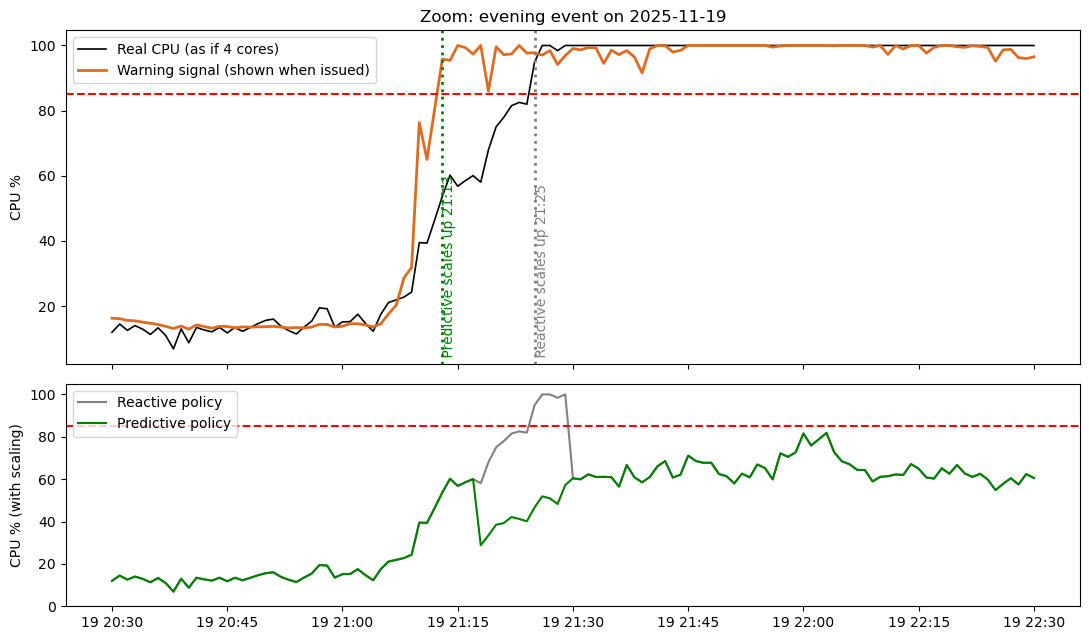

In [19]:
# ===== ZOOM: evening event on the demo day =====
z0, z1 = pd.Timestamp(demo_day + " 20:30"), pd.Timestamp(demo_day + " 22:30")
zm = (ti >= z0) & (ti <= z1); tz = ti[zm]
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax[0].plot(tz, c4t[zm], color="black", lw=1.2, label="Real CPU (as if 4 cores)")
ax[0].plot(tz, multi_fc[zm], color="#dd6b20", lw=2, label="Warning signal (shown when issued)")
ax[0].axhline(UP, color="red", ls="--")
for k, col, lab in [("predictive", "green", "Predictive scales up"), ("reactive", "grey", "Reactive scales up")]:
    ev = sims[k][zm]; ev = ev[ev["action"] == "SCALE_UP"]
    for x in ev.index:
        ax[0].axvline(x, color=col, lw=2, ls=":")
        ax[0].text(x, 3, " " + lab + " " + x.strftime("%H:%M"), color=col, rotation=90, va="bottom")
ax[0].set(ylabel="CPU %", title=f"Zoom: evening event on {demo_day}"); ax[0].legend(loc="upper left")
ax[1].plot(tz, sims["reactive"]["cpu_actual"][zm], color="grey", label="Reactive policy")
ax[1].plot(tz, sims["predictive"]["cpu_actual"][zm], color="green", label="Predictive policy")
ax[1].axhline(UP, color="red", ls="--"); ax[1].set(ylabel="CPU % (with scaling)", ylim=(0, 105)); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.savefig("fig6_zoom_evening.png", dpi=130); plt.show()